In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import statsmodels.formula.api as smf
from scipy import stats
from linearmodels.panel import PanelOLS, RandomEffects

print("Import complete")

Import complete


---
## Part 1-1 : Fixed Effects Panel Regression（固定効果パネル回帰）

**分析の目的**  
47 都道府県 × 16 年（2009–2024）のパネルデータを用いて、  
- **女性の平均初婚年齢** が合計特殊出生率に与える効果を推定する

- **プールド OLS（POLS）** は交絡変数バイアスを含む（ベースライン）  
- **固定効果モデル（FE）** は時不変の交絡（地域経済の魅力度など）を除去する  
- **変量効果モデル（RE）** と比較し、ハウスマン検定的な解釈を行う

| 変数 | 内容 |
|------|------|
| `marriage_age` | 女性の平均初婚年齢：説明変数 |
| `tfr` | 合計特殊出生率：目的変数 |

In [2]:
# ============================================================
# 定数
# ============================================================
YEARS_MAIN = list(range(2009, 2025))   # 初婚年齢×出生率（毎年データ）

# ============================================================
# 1. 生データ読み込み
# ============================================================
df_tfr_raw = pd.read_csv(
    "../data/都道府県別_合計特殊出生率.csv",
    encoding="cp932",
    skiprows=9,          # 先頭9行はメタデータ
    na_values=["…"],
)

df_age_raw = pd.read_csv(
    "../data/都道府県別_平均初婚年齢_女性.csv",
    encoding="cp932",
    skiprows=11,         # 先頭11行はメタデータ
    na_values=["…"],
)

`r"^(\d{2})"` は文字列の先頭から2桁の数字を抽出する正規表現

* `^` ：文字列の先頭
* `\d` ：数字（0〜9）
* `{2}` ：直前の\dがちょうど2回
* `( )` ：マッチした部分を抽出（キャプチャグループ）

In [3]:
# ============================================================
# 2. 前処理：都道府県列のリネーム、全国行の分離、都道府県パネルの作成
# ============================================================
def preprocess(df, value_name):
    """
    - 第1列を 'prefecture' にリネーム
    - 「全　国」行を分離して national_df として返す
    - 都道府県コード（数字2桁）を抽出して 'pref_code' 列を作成
    - wide → long 変換（tidy形式）
    - 年を int 型に変換
    - 戻り値: (都道府県のみのlong DataFrame, 全国のみのlong DataFrame)
    """
    df = df.rename(columns={df.columns[0]: "prefecture"})
    year_cols = [c for c in df.columns if str(c).isdigit()]

    def to_long(df_subset, id_vars):
        df_long = df_subset.melt(
            id_vars=id_vars,        # 列として固定したままにするもの
            value_vars=year_cols,   # 縦に展開する列
            var_name="year",        # 縦に展開した列の名前
            value_name=value_name,  # 縦に展開した列の値の列名
        )
        df_long["year"] = df_long["year"].astype(int)
        return df_long

    # 全国行を分離
    df_national = df[df["prefecture"] == "全　国"].copy()
    df_national_long = to_long(df_national, id_vars=[])

    # 都道府県のみ残す
    df_pref = df[df["prefecture"] != "全　国"].copy()
    df_pref["pref_code"] = df_pref["prefecture"].str.extract(r"^(\d{2})").astype(int)
    df_pref_long = to_long(df_pref, id_vars=["prefecture", "pref_code"])

    return df_pref_long, df_national_long

df_tfr, df_tfr_national = preprocess(df_tfr_raw, "tfr")
df_age, df_age_national = preprocess(df_age_raw, "marriage_age")

In [4]:
# ============================================================
# 3. 分析用データセット：2009〜2024年に絞ってマージ
# ============================================================
df_tfr_main = df_tfr[df_tfr["year"].isin(YEARS_MAIN)]
df_age_main = df_age[df_age["year"].isin(YEARS_MAIN)]
df_panel_age = pd.merge(
    df_tfr_main,
    df_age_main[["pref_code", "year", "marriage_age"]],
    on=["pref_code", "year"],
    how="inner",
)
df_panel_age = df_panel_age.sort_values(["pref_code", "year"]).reset_index(drop=True)

# 全国データ（可視化用）：2009〜2024年に絞ってマージ
df_national_age = pd.merge(
    df_tfr_national[df_tfr_national["year"].isin(YEARS_MAIN)],
    df_age_national[df_age_national["year"].isin(YEARS_MAIN)],
    on="year",
    how="inner",
).sort_values("year").reset_index(drop=True)

In [5]:
# ============================================================
# 4. 確認出力
# ============================================================
print("=== df_panel（先頭5行）===")
print(df_panel_age.head())
print()
print(f"行数: {len(df_panel_age)}  （期待値: 47都道府県 × {len(YEARS_MAIN)}年 = {47 * len(YEARS_MAIN)}）")
print()
print("=== 欠損値確認 ===")
print(df_panel_age.isnull().sum())
print()
print("=== 基本統計量 ===")
print(df_panel_age[["tfr", "marriage_age"]].describe().round(3))
print()
print("=== df_national_age（先頭5行）===")
print(df_national_age.head())
print()
print(f"行数: {len(df_national_age)}  （期待値: {len(YEARS_MAIN)}年）")
print()
print("=== 欠損値確認（全国）===")
print(df_national_age.isnull().sum())

=== df_panel（先頭5行）===
  prefecture  pref_code  year   tfr  marriage_age
0     01 北海道          1  2009  1.19          28.4
1     01 北海道          1  2010  1.26          28.7
2     01 北海道          1  2011  1.25          28.7
3     01 北海道          1  2012  1.26          29.0
4     01 北海道          1  2013  1.28          29.1

行数: 752  （期待値: 47都道府県 × 16年 = 752）

=== 欠損値確認 ===
prefecture      0
pref_code       0
year            0
tfr             0
marriage_age    0
dtype: int64

=== 基本統計量 ===
           tfr  marriage_age
count  752.000       752.000
mean     1.435        29.068
std      0.157         0.478
min      0.960        27.500
25%      1.330        28.800
50%      1.440        29.100
75%      1.540        29.400
max      1.960        30.700

=== df_national_age（先頭5行）===
   year   tfr  marriage_age
0  2009  1.37          28.6
1  2010  1.39          28.8
2  2011  1.39          29.0
3  2012  1.41          29.2
4  2013  1.43          29.3

行数: 16  （期待値: 16年）

=== 欠損値確認（全国）===
year        

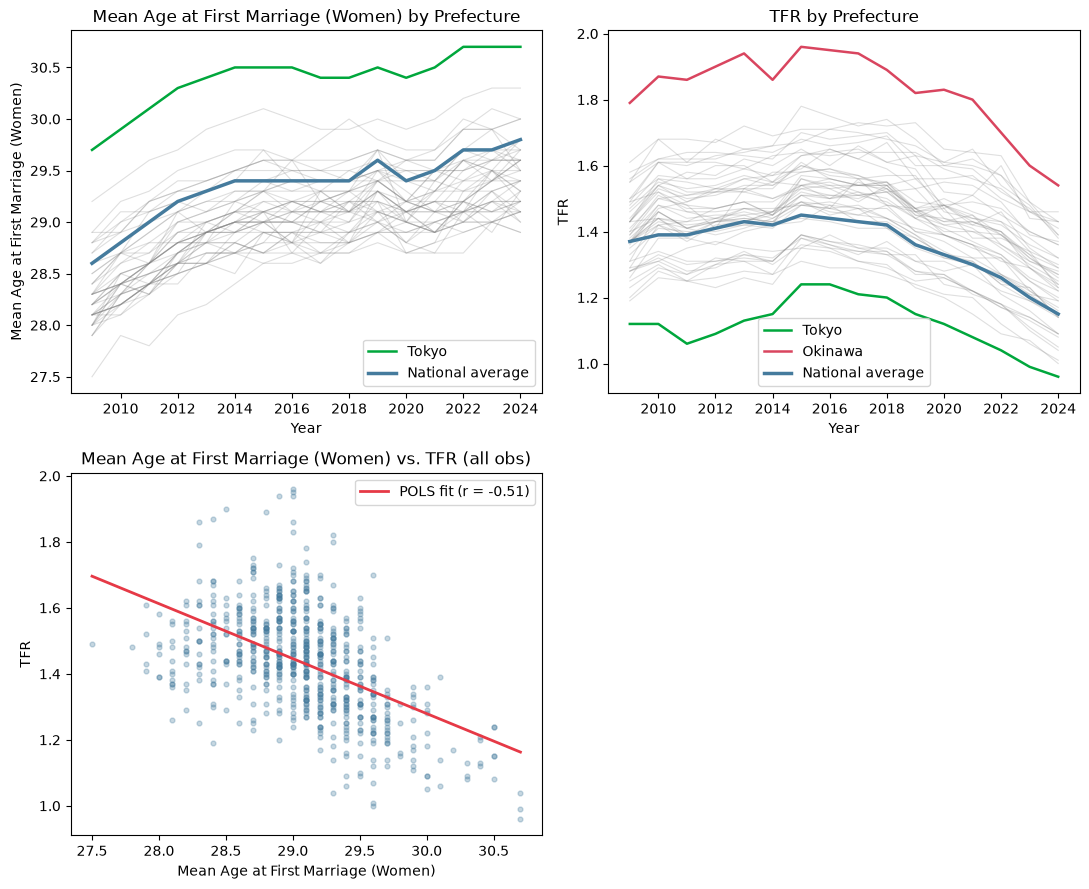

In [6]:
# ── 可視化：女性の平均初婚年齢と TFR の推移 + 散布図（1枚の画像にまとめる）───────────────
slope, intercept, r_value, p_value, std_err = stats.linregress(df_panel_age["marriage_age"], df_panel_age["tfr"])

fig, axes = plt.subplots(2, 2, figsize=(11, 9))

# 左上：女性の平均初婚年齢のスパゲッティプロット
ax = axes[0, 0]
for pref, grp in df_panel_age.groupby("pref_code"):
    if pref == 13:  # 東京都だけ色を変える
        ax.plot(grp["year"], grp["marriage_age"], linewidth=1.8, color="#00A73C", label="Tokyo", zorder=3)
    else:
        ax.plot(grp["year"], grp["marriage_age"], alpha=0.25, linewidth=0.8, color="gray")
ax.plot(df_national_age["year"], df_national_age["marriage_age"], linewidth=2.5, color="#457B9D", label="National average")
ax.set(xlabel="Year", ylabel="Mean Age at First Marriage (Women)", title="Mean Age at First Marriage (Women) by Prefecture")
ax.xaxis.set_major_locator(ticker.MultipleLocator(2))
ax.legend()

# 右上：TFR のスパゲッティプロット
ax = axes[0, 1]
for pref, grp in df_panel_age.groupby("pref_code"):
    if pref == 13:  # 東京都だけ色を変える
        ax.plot(grp["year"], grp["tfr"], linewidth=1.8, color="#00A73C", label="Tokyo", zorder=3)
    elif pref == 47:  # 沖縄県だけ色を変える
        ax.plot(grp["year"], grp["tfr"], linewidth=1.8, color="#D9455F", label="Okinawa", zorder=3)
    else:
        ax.plot(grp["year"], grp["tfr"], alpha=0.25, linewidth=0.8, color="gray")
ax.plot(df_national_age["year"], df_national_age["tfr"], linewidth=2.5, color="#457B9D", label="National average")
ax.set(xlabel="Year", ylabel="TFR", title="TFR by Prefecture")
ax.xaxis.set_major_locator(ticker.MultipleLocator(2))
ax.legend()

# 左下：散布図（POLSの回帰直線つき）
ax = axes[1, 0]
ax.scatter(df_panel_age["marriage_age"], df_panel_age["tfr"], alpha=0.3, s=12, color="#457B9D")
x_line = np.linspace(df_panel_age["marriage_age"].min(), df_panel_age["marriage_age"].max(), 100)
ax.plot(x_line, slope * x_line + intercept, color="#E63946", linewidth=2, label=f"POLS fit (r = {r_value:.2f})")
ax.set(xlabel="Mean Age at First Marriage (Women)", ylabel="TFR", title="Mean Age at First Marriage (Women) vs. TFR (all obs)")
ax.legend()

# 右下：非表示
axes[1, 1].axis("off")

plt.tight_layout()
fig.savefig("../images/plot_age_tfr_combined.png", dpi=150, bbox_inches="tight")
plt.show()

- どの都道府県も女性の平均初婚年齢の長期トレンドは上昇傾向にある。
- 合計特殊出生率は2015年頃までは緩やかな上昇傾向にあったが、以降は下落傾向にある。
- 初婚年齢と出生率の散布図を見ると、中程度の負の相関があることがわかる。

In [7]:
# ── プールド OLS（交絡バイアスのベースライン） ────────────────────────────────
# 文化や歴史的背景、経済状況など、都道府県固有の交絡変数が誤差項に入り込むため、
# 女性の平均初婚年齢の係数は真値より絶対値が大きくなる（過大推定）。

model_pols_age = smf.ols("tfr ~ marriage_age", data=df_panel_age).fit()

print(model_pols_age.summary())
print(f"\nPOLS：marriage_age 係数 = {model_pols_age.params['marriage_age']:.5f}")

                            OLS Regression Results                            
Dep. Variable:                    tfr   R-squared:                       0.258
Model:                            OLS   Adj. R-squared:                  0.257
Method:                 Least Squares   F-statistic:                     260.9
Date:                Wed, 29 Jul 2026   Prob (F-statistic):           1.39e-50
Time:                        15:08:07   Log-Likelihood:                 438.46
No. Observations:                 752   AIC:                            -872.9
Df Residuals:                     750   BIC:                            -863.7
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        6.2775      0.300     20.934   

- Durbin-Watson=0.202
- d ≈ 0 の場合：正の自己相関がある（1期前の残差と今期の残差が似た傾向を持ちやすい）

In [8]:
# ── 固定効果モデル（県 + 時間 FE） ────────────────────────────────────────────
# 県固定効果（entity_effects=True）が時不変の都道府県固有の交絡作用を吸収する。
# 時間固定効果（time_effects=True）が年次共通ショックを除去する。
# クラスター標準誤差（県単位）で系列相関に対応。

# PanelOLS は (entity, time) の MultiIndex が必要
df_fe_age = df_panel_age.set_index(["pref_code", "year"])

model_fe_age = PanelOLS(
    dependent=df_fe_age["tfr"],
    exog=df_fe_age["marriage_age"],
    entity_effects=True,   # 県固定効果
    time_effects=True      # 時間固定効果
).fit(
    cov_type="clustered",  # クラスター標準誤差
    cluster_entity=True    # クラスタリング単位：県
)

print(model_fe_age.summary)
print(f"\nFE：marriage_age 係数   = {model_fe_age.params['marriage_age']:.5f}")

                          PanelOLS Estimation Summary                           
Dep. Variable:                    tfr   R-squared:                        0.0590
Estimator:                   PanelOLS   R-squared (Between):             -3.9581
No. Observations:                 752   R-squared (Within):               0.0911
Date:                Wed, Jul 29 2026   R-squared (Overall):             -3.9442
Time:                        15:08:10   Log-likelihood                    1601.0
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      43.211
Entities:                          47   P-value                           0.0000
Avg Obs:                       16.000   Distribution:                   F(1,689)
Min Obs:                       16.000                                           
Max Obs:                       16.000   F-statistic (robust):             11.603
                            

- 女性の平均初婚年齢が1歳上がるごとに、合計特殊出生率が約0.06減少する。

- ただし擬似相関の可能性も排除できない。県内の景気悪化が出生率の低下と結婚の先延ばしを同時に引き起こすとすれば、初婚年齢と出生率の負の相関は因果関係ではなく、県内の景気という交絡変数による見かけの相関である可能性がある。

- 全国共通の景気変動は時間FEで除去されるが、県固有の景気ショックは交絡として残る可能性がある。

- 例えばある県で大手企業の工場が閉鎖した年は、その県だけ景気が悪くなり、出生率の低下と結婚の先延ばしが同時に上がる可能性がある。こういった県固有の時間変動する景気ショックは、県FEでも時間FEでも吸収できない。

| モデル| 係数 |
| --- | --- |
| プールドOLS | -0.1666 | 
| FE | -0.0609 |

- FEで係数の絶対値が約1/3に縮小
- これはプールドOLSが都道府県固有の交絡（文化・経済状況など）を誤差項に含んでいたために過大推定していたことを示している。

In [9]:
# ── 二方向within変換を手動で行い、OLS回帰で固定効果モデルを再現 ─────────────────
#
# 固定効果モデルのエッセンス：
#   各観測値から「その県の平均」と「その年の平均」を引くことで、
#   時不変の県特性（交絡因子を含む）と年次共通ショックを除去する。
#   残るのは「県内・年内の純粋なばらつき」だけで、
#   これに対してOLSを当てはめると固定効果モデルと同じ係数が得られる。
#
# 変換式：ỹ_it = y_it - ȳ_i - ȳ_t + ȳ
#   y_it : 観測値（県i、年t）
#   ȳ_i  : 県iの全期間平均  → 県固定効果（交絡因子を含む時不変特性）を除去
#   ȳ_t  : 年tの全県平均    → 時間固定効果（年次共通ショック）を除去
#   ȳ    : 全体平均         → 二重引きすぎた分を補正するために加算
#
# （説明）
# ỹ_it = y_it - (ȳ_i - ȳ) - (ȳ_t - ȳ) - ȳ
# 観測値から「県の乖離」「年の乖離」「全国全期間平均」の3つを全部引いており、
# これら3つで元のデータの構造を完全に説明し切って、残差だけを取り出している。
# 数値例で確認すると：
# y_it      = 1.30  （Hokkaido 2015年の実測値）
# ȳ         = 1.10  （全国全期間平均）
# ȳ_i - ȳ  = +0.05  （Hokkaidoの全期間平均は全国全期間平均より0.05高い）
# ȳ_t - ȳ  = -0.03  （2015年の全国平均は全国全期間平均より0.03低い）
# ỹ_it = 1.30 - 0.05 - (-0.03) - 1.10 = 0.18
# この 0.18 が「県の特性でも年の特性でも全国水準でも説明できない、
# Hokkaido固有の2015年の動き」つまり交絡に汚染されていない純粋な変動

# Step 1: 県平均・年平均・全体平均を各行に展開 ──────────────────────────────
df_panel_age["tfr_mean_pref"]    = df_panel_age.groupby("pref_code")["tfr"].transform("mean")
df_panel_age["marriage_age_mean_pref"] = df_panel_age.groupby("pref_code")["marriage_age"].transform("mean")
df_panel_age["tfr_mean_year"]    = df_panel_age.groupby("year")["tfr"].transform("mean")
df_panel_age["marriage_age_mean_year"] = df_panel_age.groupby("year")["marriage_age"].transform("mean")
df_panel_age["tfr_mean_all"]     = df_panel_age["tfr"].mean()
df_panel_age["marriage_age_mean_all"]  = df_panel_age["marriage_age"].mean()

# Step 2: 二方向within変換 ────────────────────────────────────────────────────
df_panel_age["tfr_dm_2way"]    = (df_panel_age["tfr"]
                                  - df_panel_age["tfr_mean_pref"]    # 県平均を引く（県FEの除去）
                                  - df_panel_age["tfr_mean_year"]    # 年平均を引く（時間FEの除去）
                                  + df_panel_age["tfr_mean_all"])    # 全体平均を足す（二重引きの補正）

df_panel_age["marriage_age_dm_2way"] = (df_panel_age["marriage_age"] 
                                        - df_panel_age["marriage_age_mean_pref"] 
                                        - df_panel_age["marriage_age_mean_year"] 
                                        + df_panel_age["marriage_age_mean_all"])

# Step 3: 変換後のデータでOLS ─────────────────────────────────────────────────
# - 1 で切片を除去（変換後のデータは平均0になっているため切片不要）
model_within_age_2way = smf.ols("tfr_dm_2way ~ marriage_age_dm_2way - 1", data=df_panel_age).fit()

print(model_within_age_2way.summary())
print(f"\nWithin変換 + OLS : {model_within_age_2way.params['marriage_age_dm_2way']:.5f}")
print(f"PanelOLS（参照）  : {model_fe_age.params['marriage_age']:.5f}")

                                 OLS Regression Results                                
Dep. Variable:            tfr_dm_2way   R-squared (uncentered):                   0.059
Model:                            OLS   Adj. R-squared (uncentered):              0.058
Method:                 Least Squares   F-statistic:                              47.10
Date:                Wed, 29 Jul 2026   Prob (F-statistic):                    1.41e-11
Time:                        15:08:14   Log-Likelihood:                          1601.0
No. Observations:                 752   AIC:                                     -3200.
Df Residuals:                     751   BIC:                                     -3195.
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
                           coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------

→ 二つの係数が一致することで、PanelOLSがwithin変換を内部で行っていることを確認

In [10]:
# ── 県間・県内の分解（POLSとFEで符号が逆転した理由の確認）───────────────────────
# 県間：都道府県平均同士の関係（between estimator）
df_between_age = df_panel_age.groupby("pref_code")[["tfr", "marriage_age"]].mean()
model_between_age = smf.ols("tfr ~ marriage_age", data=df_between_age).fit()

# 県内：県ごとの平均を引いた変動同士の関係（within estimator、時間FEなしの近似）
df_within_age = df_panel_age.copy()
df_within_age["tfr_dm_1way"] = df_within_age["tfr"] - df_within_age.groupby("pref_code")["tfr"].transform("mean")
df_within_age["marriage_age_dm_1way"] = df_within_age["marriage_age"] - df_within_age.groupby("pref_code")["marriage_age"].transform("mean")
model_within_age_1way = smf.ols("tfr_dm_1way ~ marriage_age_dm_1way", data=df_within_age).fit()

print("=== 県間（between）===")
print(f"係数: {model_between_age.params['marriage_age']:.4f}")
print(f"p値 : {model_between_age.pvalues['marriage_age']:.4f}")
print()
print("=== 県内（within）===")
print(f"係数: {model_within_age_1way.params['marriage_age_dm_1way']:.4f}")
print(f"p値 : {model_within_age_1way.pvalues['marriage_age_dm_1way']:.4f}")
print()

# 参考：分散の大きさ（POLSがどちらに引っ張られやすいかの目安）
var_between_age = df_between_age["marriage_age"].var()
var_within_age = df_within_age["marriage_age_dm_1way"].var()
print("=== 分散の内訳 ===")
print(f"Var(between): {var_between_age:.4f}")
print(f"Var(within) : {var_within_age:.4f}")

=== 県間（between）===
係数: -0.2516
p値 : 0.0000

=== 県内（within）===
係数: -0.0782
p値 : 0.0000

=== 分散の内訳 ===
Var(between): 0.1191
Var(within) : 0.1122


weight_between = 0.1191 / (0.1122 + 0.1191) = 0.515

weight_within  = 0.1122 / (0.1122 + 0.1191) = 0.485

加重平均 = 0.515 × (-0.2516) + 0.485 × (-0.0782)
        = -0.1296 + (-0.0379)
        = -0.1675
        
実際のPOLS = -0.1666  ← ほぼ一致

In [11]:
# ── 変量効果モデル（RE）との比較 ──────────────────────────────────────────────
# RE は交絡変数と説明変数が無相関という仮定が必要。

model_re_age = RandomEffects(
    dependent=df_fe_age["tfr"],
    exog=df_fe_age["marriage_age"]
).fit()

print("=== 変量効果モデル（RE）===")
print(model_re_age.summary)

print("\n=== FE / RE / POLS の比較 ===")
print(f"POLS 係数 : {model_pols_age.params['marriage_age']:.5f}  （交絡バイアスあり）")
print(f"RE   係数 : {model_re_age.params['marriage_age']:.5f}")
print(f"FE   係数 : {model_fe_age.params['marriage_age']:.5f}  （交絡を除去）")
print(f"\nFE と RE の差: {abs(model_fe_age.params['marriage_age'] - model_re_age.params['marriage_age']):.5f}")
print("差が大きい → 交絡ありと判断し FE を採用")
print("差が小さい → RE も検討可（効率性が高い）")

=== 変量効果モデル（RE）===
                        RandomEffects Estimation Summary                        
Dep. Variable:                    tfr   R-squared:                        0.8249
Estimator:              RandomEffects   R-squared (Between):              0.9898
No. Observations:                 752   R-squared (Within):              -0.1555
Date:                Wed, Jul 29 2026   R-squared (Overall):              0.9859
Time:                        15:08:21   Log-likelihood                    716.49
Cov. Estimator:            Unadjusted                                           
                                        F-statistic:                      3537.5
Entities:                          47   P-value                           0.0000
Avg Obs:                       16.000   Distribution:                   F(1,751)
Min Obs:                       16.000                                           
Max Obs:                       16.000   F-statistic (robust):             3537.5
         

In [12]:
# ── ハウスマン検定（手動実装） ─────────────────────────────────────────────────
# linearmodels に hausman 関数は実装されていないため手動で計算する。
# 帰無仮説：REは一致推定量（交絡なし）
# 対立仮説：FEのみ一致推定量（交絡あり）

b_fe_age   = model_fe_age.params.values
b_re_age   = model_re_age.params.values
diff_age   = b_fe_age - b_re_age

# FEとREの分散共分散行列の差
V_diff_age = model_fe_age.cov.values - model_re_age.cov.values

# カイ二乗統計量 H = diff' * V_diff^{-1} * diff
H_age       = float(diff_age @ np.linalg.pinv(V_diff_age) @ diff_age)
df_stat_age = len(diff_age)
p_value_age = 1 - stats.chi2.cdf(H_age, df=df_stat_age)

print(f"ハウスマン検定統計量 : {H_age:.4f}")
print(f"自由度               : {df_stat_age}")
print(f"p値                  : {p_value_age:.4f}")
print()
if p_value_age < 0.05:
    print("p値 < 0.05 → FEとREに有意な差あり → FEを採用")
else:
    print("p値 >= 0.05 → 差は誤差の範囲内 → REも検討可")

ハウスマン検定統計量 : 37.4999
自由度               : 1
p値                  : 0.0000

p値 < 0.05 → FEとREに有意な差あり → FEを採用


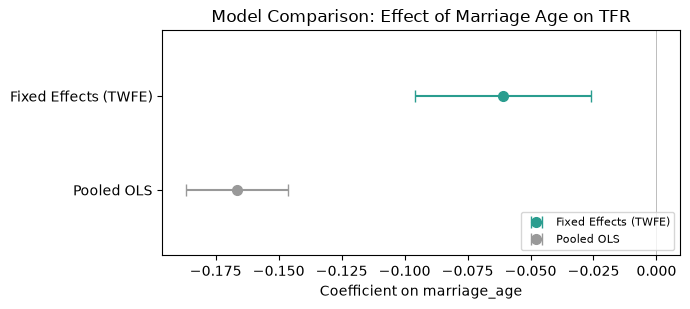

In [13]:
# ── 係数比較プロット（フォレストプロット風）───────────────────────────────────
# 2 モデルの marriage_age 係数と 95% CI を並べる。
# 各モデルの係数・CI を収集
pols_coef_age = model_pols_age.params["marriage_age"]
pols_ci_age   = model_pols_age.conf_int().loc["marriage_age"]
fe_coef_age = model_fe_age.params["marriage_age"]
fe_ci_age   = model_fe_age.conf_int().loc["marriage_age"]
model_labels = ["Pooled OLS", "Fixed Effects (TWFE)"]
coefs_age  = [pols_coef_age, fe_coef_age]
ci_los_age = [pols_ci_age.iloc[0], fe_ci_age.iloc[0]]
ci_his_age = [pols_ci_age.iloc[1], fe_ci_age.iloc[1]]
colors_dot = ["#999999", "#2A9D8F"]
fig, ax = plt.subplots(figsize=(7, 3.2))
for i, (label, coef, lo, hi, col) in enumerate(
        zip(model_labels, coefs_age, ci_los_age, ci_his_age, colors_dot)):
    ax.errorbar(coef, i,
                xerr=[[coef - lo], [hi - coef]],
                fmt="o", color=col, ecolor=col,
                capsize=4, markersize=7, linewidth=1.5,
                label=label)
ax.axvline(0, color="black", linestyle="-", linewidth=0.6, alpha=0.3)
ax.set_yticks(range(len(model_labels)))
ax.set_yticklabels(model_labels)
ax.set_ylim(-0.7, len(model_labels) - 0.3)  # 上下に余白を持たせて中央に寄せる
ax.set_xlabel("Coefficient on marriage_age")
ax.set_title("Model Comparison: Effect of Marriage Age on TFR")
# 凡例の順序を逆にする
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], fontsize=8, loc="lower right")

plt.tight_layout()
fig.savefig("../images/model_comparison_age.png", dpi=150, bbox_inches="tight")
plt.show()

---
## Part 1-2 : Fixed Effects Panel Regression（固定効果パネル回帰）

**分析の目的**  
47 都道府県 × 4 時点（2007, 2012, 2017, 2022）のパネルデータを用いて、  
- **非正規雇用率** が合計特殊出生率に与える効果を推定する

- **プールド OLS（POLS）** は交絡変数バイアスを含む（ベースライン）  
- **固定効果モデル（FE）** は時不変の交絡（地域経済の魅力度など）を除去する  
- **変量効果モデル（RE）** と比較し、ハウスマン検定的な解釈を行う

| 変数 | 内容 |
|------|------|
| `nonregular_rate` | 非正規雇用率：説明変数 |
| `tfr` | 合計特殊出生率：目的変数 |

In [14]:
# ============================================================
# 非正規雇用率の定義
#   非正規率 = 非正規の職員・従業員数 ÷ 雇用者総数（役員含む）× 100
#   ※ 2017年の集計済み比率（正規58.3%＋非正規36.0%＝94.3%）で確認済み
#   ※ 自営業主・家族従業者は分母に含めない
# ============================================================


def load_2007(path):
    """
    2007年就業構造基本調査
    シート: A007-1（全国＋都道府県が全部入り）
    列構造:
        col7  = 都道府県名
        col24 = 正規の職員・従業員（人数）
        col25 = パート（人数）
        col26 = アルバイト（人数）
        col27 = 労働者派遣（人数）
        col28 = 契約社員（人数）
        col29 = 嘱託（人数）
        col30 = その他（人数）
    → 非正規合計 = col25〜col30 の合計
    """
    df = pd.read_excel(path, sheet_name="A007-1", engine="xlrd", header=None)

    # データ行：行14以降、都道府県名列（col7）が文字列の行のみ
    df_data = df.iloc[14:].copy()
    df_data = df_data[df_data[7].astype(str).str.strip() != "nan"].copy()

    # 全国行を除外
    df_data = df_data[~df_data[7].astype(str).str.contains("全国")].copy()

    # 都道府県コード（col8）を取得
    df_data["pref_code"] = df_data[8].astype(float).astype(int) - 1  # 2→1, 3→2...
    # ※ col8は1=全国, 2=北海道, ... なので -1 でコード化

    # 正規・非正規の人数、雇用者総数（役員含む）
    df_data["非正規"] = (
        df_data[25].astype(float)  # パート
        + df_data[26].astype(float)  # アルバイト
        + df_data[27].astype(float)  # 派遣
        + df_data[28].astype(float)  # 契約
        + df_data[29].astype(float)  # 嘱託
        + df_data[30].astype(float)  # その他
    )
    df_data["雇用者総数"] = df_data[16].astype(float)  # 役員含む雇用者総数
    df_data["nonregular_rate"] = df_data["非正規"] / df_data["雇用者総数"] * 100
    df_data["year"] = 2007

    return df_data[["pref_code", "year", "nonregular_rate"]].reset_index(drop=True)

In [15]:
def load_2007_national(path):
    """2007年調査の「全国」行のみを抽出（シート・列構造はload_2007と同じ）"""
    df = pd.read_excel(path, sheet_name="A007-1", engine="xlrd", header=None)
    df_data = df.iloc[14:].copy()
    df_data = df_data[df_data[7].astype(str).str.strip() != "nan"].copy()
    df_national = df_data[df_data[7].astype(str).str.contains("全国")].copy()
    df_national["非正規"] = (
        df_national[25].astype(float)
        + df_national[26].astype(float)
        + df_national[27].astype(float)
        + df_national[28].astype(float)
        + df_national[29].astype(float)
        + df_national[30].astype(float)
    )
    df_national["雇用者総数"] = df_national[16].astype(float)
    df_national["nonregular_rate"] = df_national["非正規"] / df_national["雇用者総数"] * 100
    df_national["year"] = 2007
    return df_national[["year", "nonregular_rate"]].reset_index(drop=True)

In [16]:
def load_2012(path):
    """
    2012年就業構造基本調査
    シート: B008-1
    列構造:
        col7  = 都道府県名
        col8  = 行番号（2=北海道, 3=青森, ...）
        col21 = 正規の職員・従業員（人数）
        col22 = 非正規の職員・従業員の総数（人数）
    """
    df = pd.read_excel(path, sheet_name="B008-1", engine="xlrd", header=None)

    df_data = df.iloc[16:].copy()
    df_data = df_data[df_data[8].notna()].copy()           # col8（行番号）がある行のみ
    df_data = df_data[~df_data[7].astype(str).str.contains("全国")].copy()

    df_data["pref_code"] = df_data[8].astype(float).astype(int) - 1

    df_data["非正規"] = df_data[22].astype(float)
    df_data["雇用者総数"] = df_data[16].astype(float)  # 役員含む雇用者総数
    df_data["nonregular_rate"] = df_data["非正規"] / df_data["雇用者総数"] * 100
    df_data["year"] = 2012

    return df_data[["pref_code", "year", "nonregular_rate"]].reset_index(drop=True)

In [17]:
def load_2012_national(path):
    """2012年調査の「全国」行のみを抽出（シート・列構造はload_2012と同じ）"""
    df = pd.read_excel(path, sheet_name="B008-1", engine="xlrd", header=None)
    df_data = df.iloc[16:].copy()
    df_data = df_data[df_data[8].notna()].copy()
    df_national = df_data[df_data[7].astype(str).str.contains("全国")].copy()
    df_national["非正規"] = df_national[22].astype(float)
    df_national["雇用者総数"] = df_national[16].astype(float)
    df_national["nonregular_rate"] = df_national["非正規"] / df_national["雇用者総数"] * 100
    df_national["year"] = 2012
    return df_national[["year", "nonregular_rate"]].reset_index(drop=True)

In [18]:
def load_2017(path):
    """
    2017年就業構造基本調査
    シート: c008_03（1シートに全都道府県）
    列構造（long形式）:
        col5  = 地域区分（例: '00_全国', '01_北海道'）
        col6  = 男女
        col7  = 年齢
        col13 = 雇用者に占める比率（非正規の職員・従業員）[%]
    → 男女=総数、年齢=総数の行のみ使用
    """
    df = pd.read_excel(path, sheet_name="c008_03", engine="openpyxl", header=None)

    # データ行：行15以降
    df_data = df.iloc[15:].copy()
    df_data.columns = range(len(df_data.columns))

    # 都道府県レベル（地域コードが '01_'〜'47_' 形式）、男女=総数、年齢=総数
    mask = (
        (df_data[6] == "0_総数") &
        (df_data[7] == "0_総数") &
        (df_data[5].astype(str).str.match(r"^\d{2}_")) &
        (~df_data[5].astype(str).str.startswith("00_"))
    )
    df_pref = df_data[mask].copy()

    # extract()はパターン全体にマッチした文字列ではなく、カッコの中だけを取り出す
    df_pref["pref_code"] = df_pref[5].astype(str).str.extract(r"^(\d{2})_").astype(int)
    df_pref["nonregular_rate"] = df_pref[13].astype(float)
    df_pref["year"] = 2017

    return df_pref[["pref_code", "year", "nonregular_rate"]].reset_index(drop=True)

In [19]:
def load_2017_national(path):
    """2017年調査の「00_全国」行のみを抽出（シート・列構造はload_2017と同じ）"""
    df = pd.read_excel(path, sheet_name="c008_03", engine="openpyxl", header=None)
    df_data = df.iloc[15:].copy()
    df_data.columns = range(len(df_data.columns))
    mask = (
        (df_data[6] == "0_総数") &
        (df_data[7] == "0_総数") &
        (df_data[5].astype(str).str.startswith("00_"))
    )
    df_national = df_data[mask].copy()
    df_national["nonregular_rate"] = df_national[13].astype(float)
    df_national["year"] = 2017
    return df_national[["year", "nonregular_rate"]].reset_index(drop=True)

In [20]:
def load_2022(path):
    """
    2022年就業構造基本調査
    シート: b008_01（long形式）
    列構造:
        col1  = 地域区分（例: '01_北海道'）
        col3  = 男女
        col5  = 年齢
        col7  = 教育
        col19 = 321_正規の職員・従業員（人数）
        col20 = 322_非正規の職員・従業員（人数）
    → 男女=総数、年齢=総数、教育=総数の行のみ使用
    """
    df = pd.read_excel(path, sheet_name="b008_01", engine="openpyxl", header=None)

    df_data = df.iloc[9:].copy()
    df_data.columns = range(len(df_data.columns))

    mask = (
        (df_data[3] == "0_総数") &
        (df_data[5] == "00_総数") &
        (df_data[7] == "0_総数") &
        (df_data[1].astype(str).str.match(r"^\d{2}_")) &
        (df_data[1] != "00_全国")
    )
    df_pref = df_data[mask].copy()

    df_pref["pref_code"] = df_pref[1].astype(str).str.extract(r"^(\d{2})_").astype(int)
    df_pref["非正規"] = df_pref[20].astype(float)
    df_pref["雇用者総数"] = df_pref[15].astype(float)  # 役員含む雇用者総数
    df_pref["nonregular_rate"] = df_pref["非正規"] / df_pref["雇用者総数"] * 100
    df_pref["year"] = 2022

    return df_pref[["pref_code", "year", "nonregular_rate"]].reset_index(drop=True)

In [21]:
def load_2022_national(path):
    """2022年調査の「00_全国」行のみを抽出（シート・列構造はload_2022と同じ）"""
    df = pd.read_excel(path, sheet_name="b008_01", engine="openpyxl", header=None)
    df_data = df.iloc[9:].copy()
    df_data.columns = range(len(df_data.columns))
    mask = (
        (df_data[3] == "0_総数") &
        (df_data[5] == "00_総数") &
        (df_data[7] == "0_総数") &
        (df_data[1] == "00_全国")
    )
    df_national = df_data[mask].copy()
    df_national["非正規"] = df_national[20].astype(float)
    df_national["雇用者総数"] = df_national[15].astype(float)
    df_national["nonregular_rate"] = df_national["非正規"] / df_national["雇用者総数"] * 100
    df_national["year"] = 2022
    return df_national[["year", "nonregular_rate"]].reset_index(drop=True)

In [22]:
# ============================================================
# 4時点を結合
# ============================================================
BASE = "../data/"

df_nr = pd.concat([
    load_2007(BASE + "2007年_就業構造基本調査.xls"),
    load_2012(BASE + "2012年_就業構造基本調査.xls"),
    load_2017(BASE + "2017年_就業構造基本調査.xlsx"),
    load_2022(BASE + "2022年_就業構造基本調査.xlsx"),
], ignore_index=True)

df_nr = df_nr.sort_values(["pref_code", "year"]).reset_index(drop=True)

df_nr_national = pd.concat([
    load_2007_national(BASE + "2007年_就業構造基本調査.xls"),
    load_2012_national(BASE + "2012年_就業構造基本調査.xls"),
    load_2017_national(BASE + "2017年_就業構造基本調査.xlsx"),
    load_2022_national(BASE + "2022年_就業構造基本調査.xlsx"),
], ignore_index=True).sort_values("year").reset_index(drop=True)

In [23]:
# ============================================================
# 確認出力
# ============================================================
print("=== df_nr（先頭10行）===")
print(df_nr.head(10))
print()
print(f"行数: {len(df_nr)}  （期待値: 47都道府県 × 4時点 = 188）")
print()
print("=== 欠損値確認 ===")
print(df_nr.isnull().sum())
print()
print("=== 年別の件数と非正規率（全国平均）===")
print(df_nr.groupby("year")["nonregular_rate"].agg(["count", "mean"]).round(2))
print()
print("=== 基本統計量 ===")
print(df_nr["nonregular_rate"].describe().round(2))
print()
print("=== df_nr_national ===")
print(df_nr_national)

=== df_nr（先頭10行）===
   pref_code  year  nonregular_rate
0          1  2007        35.423185
1          1  2012        40.225343
2          1  2017        38.200000
3          1  2022        37.504682
4          2  2007        32.203994
5          2  2012        36.006699
6          2  2017        33.700000
7          2  2022        33.789954
8          3  2007        31.792815
9          3  2012        35.862692

行数: 188  （期待値: 47都道府県 × 4時点 = 188）

=== 欠損値確認 ===
pref_code          0
year               0
nonregular_rate    0
dtype: int64

=== 年別の件数と非正規率（全国平均）===
      count   mean
year              
2007     47  32.27
2012     47  35.34
2017     47  35.47
2022     47  34.56

=== 基本統計量 ===
count    188.00
mean      34.41
std        2.73
min       27.36
25%       32.69
50%       34.27
75%       36.43
max       42.98
Name: nonregular_rate, dtype: float64

=== df_nr_national ===
   year  nonregular_rate
0  2007        32.996707
1  2012        35.831486
2  2017        36.000000
3  2022      

In [24]:
# ============================================================
# 分析用データセット
# ============================================================

df_panel_nr = pd.merge(
    df_tfr,
    df_nr,
    on=["pref_code", "year"],
    how="inner",
)

df_panel_nr = df_panel_nr.sort_values(["pref_code", "year"]).reset_index(drop=True)

In [25]:
# ============================================================
# 確認出力
# ============================================================
print("=== df_panel_nr（先頭10行）===")
print(df_panel_nr.head(10))
print()
print(f"行数: {len(df_panel_nr)}  （期待値: 47都道府県 × 4時点 = {47 * 4}）")
print()
print("=== 欠損値確認 ===")
print(df_panel_nr.isnull().sum())
print()
print("=== 基本統計量 ===")
print(df_panel_nr[["tfr", "nonregular_rate"]].describe().round(3))

=== df_panel_nr（先頭10行）===
  prefecture  pref_code  year   tfr  nonregular_rate
0     01 北海道          1  2007  1.19        35.423185
1     01 北海道          1  2012  1.26        40.225343
2     01 北海道          1  2017  1.29        38.200000
3     01 北海道          1  2022  1.12        37.504682
4     02 青森県          2  2007  1.28        32.203994
5     02 青森県          2  2012  1.36        36.006699
6     02 青森県          2  2017  1.43        33.700000
7     02 青森県          2  2022  1.24        33.789954
8     03 岩手県          3  2007  1.39        31.792815
9     03 岩手県          3  2012  1.44        35.862692

行数: 188  （期待値: 47都道府県 × 4時点 = 188）

=== 欠損値確認 ===
prefecture         0
pref_code          0
year               0
tfr                0
nonregular_rate    0
dtype: int64

=== 基本統計量 ===
           tfr  nonregular_rate
count  188.000          188.000
mean     1.428           34.407
std      0.150            2.733
min      1.040           27.363
25%      1.330           32.689
50%      1.430 

In [26]:
df_panel_nr_national = pd.merge(
    df_tfr_national,
    df_nr_national,
    on="year",
    how="inner",
)
df_panel_nr_national = df_panel_nr_national.sort_values("year").reset_index(drop=True)

print("=== df_panel_nr_national ===")
print(df_panel_nr_national)
print()
print(f"行数: {len(df_panel_nr_national)}  （期待値: 4時点）")
print()
print("=== 欠損値確認 ===")
print(df_panel_nr_national.isnull().sum())

=== df_panel_nr_national ===
   year   tfr  nonregular_rate
0  2007  1.34        32.996707
1  2012  1.41        35.831486
2  2017  1.43        36.000000
3  2022  1.26        34.736828

行数: 4  （期待値: 4時点）

=== 欠損値確認 ===
year               0
tfr                0
nonregular_rate    0
dtype: int64


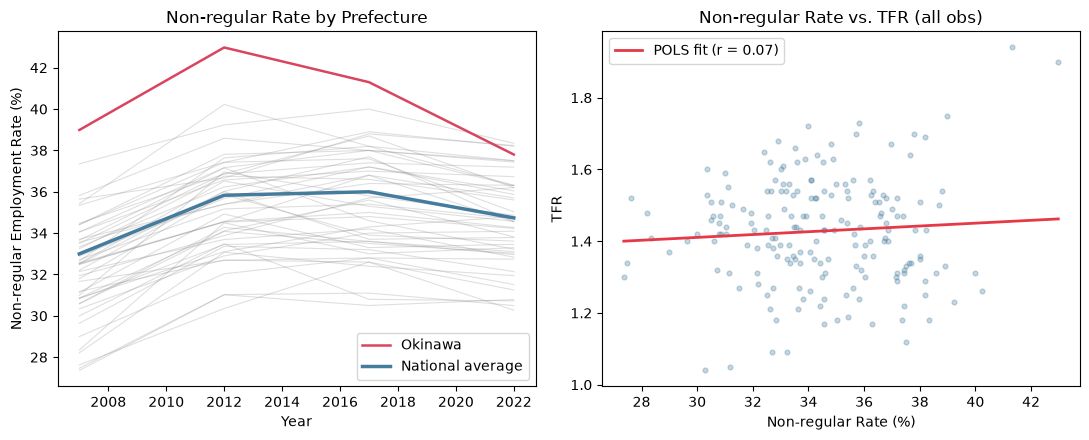

In [27]:
# ── 可視化：非正規雇用率と TFR の推移 + 散布図（1枚の画像にまとめる）───────────────
slope, intercept, r_value, p_value, std_err = stats.linregress(df_panel_nr["nonregular_rate"], df_panel_nr["tfr"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# 左：非正規雇用率のスパゲッティプロット
ax = axes[0]
for pref, grp in df_panel_nr.groupby("pref_code"):
    if pref == 47:  # 沖縄県だけ色を変える
        ax.plot(grp["year"], grp["nonregular_rate"], linewidth=1.8, color="#D9455F", label="Okinawa", zorder=3)
    else:
        ax.plot(grp["year"], grp["nonregular_rate"], alpha=0.25, linewidth=0.8, color="gray")
ax.plot(df_panel_nr_national["year"], df_panel_nr_national["nonregular_rate"], linewidth=2.5, color="#457B9D", label="National average")
ax.set(xlabel="Year", ylabel="Non-regular Employment Rate (%)", title="Non-regular Rate by Prefecture")
ax.xaxis.set_major_locator(ticker.MultipleLocator(2))
ax.legend()

# 右：散布図（POLSの回帰直線つき）
ax = axes[1]
ax.scatter(df_panel_nr["nonregular_rate"], df_panel_nr["tfr"], alpha=0.3, s=12, color="#457B9D")
x_line = np.linspace(df_panel_nr["nonregular_rate"].min(), df_panel_nr["nonregular_rate"].max(), 100)
ax.plot(x_line, slope * x_line + intercept, color="#E63946", linewidth=2, label=f"POLS fit (r = {r_value:.2f})")
ax.set(xlabel="Non-regular Rate (%)", ylabel="TFR", title="Non-regular Rate vs. TFR (all obs)")
ax.legend()

plt.tight_layout()
fig.savefig("../images/plot_nr_tfr_combined.png", dpi=150, bbox_inches="tight")
plt.show()

- 非正規雇用率は2017年をピークに低下傾向
- 非正規雇用率と合計特殊出生率はほぼ無相関

In [28]:
# ── プールド OLS（交絡バイアスのベースライン） ────────────────────────────────

model_pols_nr = smf.ols("tfr ~ nonregular_rate", data=df_panel_nr).fit()

print(model_pols_nr.summary())
print(f"\nPOLS：nonregular_rate 係数 = {model_pols_nr.params['nonregular_rate']:.5f}")

                            OLS Regression Results                            
Dep. Variable:                    tfr   R-squared:                       0.005
Model:                            OLS   Adj. R-squared:                 -0.000
Method:                 Least Squares   F-statistic:                    0.9768
Date:                Wed, 29 Jul 2026   Prob (F-statistic):              0.324
Time:                        15:09:22   Log-Likelihood:                 90.865
No. Observations:                 188   AIC:                            -177.7
Df Residuals:                     186   BIC:                            -171.3
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept           1.2916      0.139     

In [29]:
# ── 固定効果モデル（県 + 時間 FE） ────────────────────────────────────────────
# 県固定効果（entity_effects=True）が時不変の都道府県固有の交絡作用を吸収する。
# 時間固定効果（time_effects=True）が年次共通ショックを除去する。
# クラスター標準誤差（県単位）で系列相関に対応。

# PanelOLS は (entity, time) の MultiIndex が必要
df_fe_nr = df_panel_nr.set_index(["pref_code", "year"])

model_fe_nr = PanelOLS(
    dependent=df_fe_nr["tfr"],
    exog=df_fe_nr["nonregular_rate"],
    entity_effects=True,   # 県固定効果
    time_effects=True      # 時間固定効果
).fit(
    cov_type="clustered",  # クラスター標準誤差
    cluster_entity=True    # クラスタリング単位：県
)

print(model_fe_nr.summary)
print(f"\nFE：nonregular 係数   = {model_fe_nr.params['nonregular_rate']:.5f}")

                          PanelOLS Estimation Summary                           
Dep. Variable:                    tfr   R-squared:                        0.0581
Estimator:                   PanelOLS   R-squared (Between):              0.4384
No. Observations:                 188   R-squared (Within):               0.2014
Date:                Wed, Jul 29 2026   R-squared (Overall):              0.4379
Time:                        15:09:26   Log-likelihood                    382.43
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      8.4443
Entities:                          47   P-value                           0.0043
Avg Obs:                       4.0000   Distribution:                   F(1,137)
Min Obs:                       4.0000                                           
Max Obs:                       4.0000   F-statistic (robust):             5.6194
                            

- 非正規雇用率が1%pt上がるごとに、合計特殊出生率が約0.01上昇する。

| モデル | 係数 | p値 |
| --- | --- | --- |
| プールドOLS | +0.00397 | 0.324（有意でない） | 
| FE | +0.01052 | 0.019（有意） |

直感に反した正の係数について

1. 擬似相関の可能性：県内の好景気が出生率の上昇と非正規雇用率の上昇（パート・アルバイト）を同時に引き起こすとすれば、非正規雇用率と出生率の正の相関は因果関係ではなく、県内の景気という交絡変数による見かけの相関である可能性がある。
- 全国共通の景気変動は時間FEで除去されるが、県固有の景気ショックは交絡として残る可能性がある。
- 例えばある県でトヨタの工場が拡張した年は、その県だけ景気が良くなり、非正規雇用率と出生率が同時に上がる可能性がある。こういった県固有の時間変動する景気ショックは、県FEでも時間FEでも吸収できない。

2. 時間FEの影響：4時点しかないため、時間固定効果が年ごとの共通トレンドをかなり吸収してしまい、係数の識別に使える県内の時間変動が限られる。

→ FEでも正の係数が得られたが、擬似相関やデータの時点数の少なさから因果解釈には慎重を要するが、3本目のOECDのジニ係数と整合性の取れる結果であることから、非正規雇用率と出生率の関係は単純な負の関係ではない可能性を示唆している。

In [30]:
# ── 二方向within変換を手動で行い、OLS回帰で固定効果モデルを再現 ─────────────────
#
# 固定効果モデルのエッセンス：
#   各観測値から「その県の平均」と「その年の平均」を引くことで、
#   時不変の県特性（交絡因子を含む）と年次共通ショックを除去する。
#   残るのは「県内・年内の純粋なばらつき」だけで、
#   これに対してOLSを当てはめると固定効果モデルと同じ係数が得られる。
#
# 変換式：ỹ_it = y_it - ȳ_i - ȳ_t + ȳ
#   y_it : 観測値（県i、年t）
#   ȳ_i  : 県iの全期間平均  → 県固定効果（交絡因子を含む時不変特性）を除去
#   ȳ_t  : 年tの全県平均    → 時間固定効果（年次共通ショック）を除去
#   ȳ    : 全体平均         → 二重引きすぎた分を補正するために加算
#
# （説明）
# ỹ_it = y_it - (ȳ_i - ȳ) - (ȳ_t - ȳ) - ȳ
# 観測値から「県の乖離」「年の乖離」「全国全期間平均」の3つを全部引いており、
# これら3つで元のデータの構造を完全に説明し切って、残差だけを取り出している。
# 数値例で確認すると：
# y_it      = 1.30  （Hokkaido 2015年の実測値）
# ȳ         = 1.10  （全国全期間平均）
# ȳ_i - ȳ  = +0.05  （Hokkaidoの全期間平均は全国全期間平均より0.05高い）
# ȳ_t - ȳ  = -0.03  （2015年の全国平均は全国全期間平均より0.03低い）
# ỹ_it = 1.30 - 0.05 - (-0.03) - 1.10 = 0.18
# この 0.18 が「県の特性でも年の特性でも全国水準でも説明できない、
# Hokkaido固有の2015年の動き」つまり交絡に汚染されていない純粋な変動

# Step 1: 県平均・年平均・全体平均を各行に展開 ──────────────────────────────
df_panel_nr["tfr_mean_pref"]    = df_panel_nr.groupby("pref_code")["tfr"].transform("mean")
df_panel_nr["nonregular_rate_mean_pref"] = df_panel_nr.groupby("pref_code")["nonregular_rate"].transform("mean")
df_panel_nr["tfr_mean_year"]    = df_panel_nr.groupby("year")["tfr"].transform("mean")
df_panel_nr["nonregular_rate_mean_year"] = df_panel_nr.groupby("year")["nonregular_rate"].transform("mean")
df_panel_nr["tfr_mean_all"]     = df_panel_nr["tfr"].mean()
df_panel_nr["nonregular_rate_mean_all"]  = df_panel_nr["nonregular_rate"].mean()

# Step 2: 二方向within変換 ────────────────────────────────────────────────────
df_panel_nr["tfr_dm_2way"]    = (df_panel_nr["tfr"]
                                 - df_panel_nr["tfr_mean_pref"]    # 県平均を引く（県FEの除去）
                                 - df_panel_nr["tfr_mean_year"]    # 年平均を引く（時間FEの除去）
                                 + df_panel_nr["tfr_mean_all"])    # 全体平均を足す（二重引きの補正）

df_panel_nr["nonregular_rate_dm_2way"] = (df_panel_nr["nonregular_rate"] 
                                          - df_panel_nr["nonregular_rate_mean_pref"] 
                                          - df_panel_nr["nonregular_rate_mean_year"] 
                                          + df_panel_nr["nonregular_rate_mean_all"])

# Step 3: 変換後のデータでOLS ─────────────────────────────────────────────────
# - 1 で切片を除去（変換後のデータは平均0になっているため切片不要）
model_within_nr_2way = smf.ols("tfr_dm_2way ~ nonregular_rate_dm_2way - 1", data=df_panel_nr).fit()

print(model_within_nr_2way.summary())
print(f"\nWithin変換 + OLS : {model_within_nr_2way.params['nonregular_rate_dm_2way']:.5f}")
print(f"PanelOLS（参照）  : {model_fe_nr.params['nonregular_rate']:.5f}")

                                 OLS Regression Results                                
Dep. Variable:            tfr_dm_2way   R-squared (uncentered):                   0.058
Model:                            OLS   Adj. R-squared (uncentered):              0.053
Method:                 Least Squares   F-statistic:                              11.53
Date:                Wed, 29 Jul 2026   Prob (F-statistic):                    0.000838
Time:                        15:09:32   Log-Likelihood:                          382.43
No. Observations:                 188   AIC:                                     -762.9
Df Residuals:                     187   BIC:                                     -759.6
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
                              coef    std err          t      P>|t|      [0.025      0.975]
----------------------------

→ 二つの係数が一致することで、PanelOLSがwithin変換を内部で行っていることを確認

In [31]:
# ── 県間・県内の分解（POLSとFEで符号が逆転した理由の確認）───────────────────────
# 県間：都道府県平均同士の関係（between estimator）
df_between_nr = df_panel_nr.groupby("pref_code")[["tfr", "nonregular_rate"]].mean()
model_between_nr = smf.ols("tfr ~ nonregular_rate", data=df_between_nr).fit()

# 県内：県ごとの平均を引いた変動同士の関係（within estimator、時間FEなしの近似）
df_within_nr = df_panel_nr.copy()
df_within_nr["tfr_dm_1way"] = df_within_nr["tfr"] - df_within_nr.groupby("pref_code")["tfr"].transform("mean")
df_within_nr["nonregular_rate_dm_1way"] = df_within_nr["nonregular_rate"] - df_within_nr.groupby("pref_code")["nonregular_rate"].transform("mean")
model_within_nr_1way = smf.ols("tfr_dm_1way ~ nonregular_rate_dm_1way", data=df_within_nr).fit()

print("=== 県間（between）===")
print(f"係数: {model_between_nr.params['nonregular_rate']:.4f}")
print(f"p値 : {model_between_nr.pvalues['nonregular_rate']:.4f}")
print()
print("=== 県内（within）===")
print(f"係数: {model_within_nr_1way.params['nonregular_rate_dm_1way']:.4f}")
print(f"p値 : {model_within_nr_1way.pvalues['nonregular_rate_dm_1way']:.4f}")
print()

# 参考：分散の大きさ（POLSがどちらに引っ張られやすいかの目安）
var_between_nr = df_between_nr["nonregular_rate"].var()
var_within_nr = df_within_nr["nonregular_rate_dm_1way"].var()
print("=== 分散の内訳 ===")
print(f"Var(between): {var_between_nr:.4f}")
print(f"Var(within) : {var_within_nr:.4f}")

=== 県間（between）===
係数: -0.0055
p値 : 0.5240

=== 県内（within）===
係数: 0.0264
p値 : 0.0000

=== 分散の内訳 ===
Var(between): 5.3366
Var(within) : 2.2164


weight_between = 5.3366 / (5.3366 + 2.2164) = 0.707

weight_within  = 2.2164 / (5.3366 + 2.2164) = 0.293

加重平均 = 0.707 × (-0.0055) + 0.293 × 0.0264
        = -0.0039 + 0.0077
        = 0.00385
        
実際のPOLS = 0.00397  ← ほぼ一致

In [32]:
# ── 変量効果モデル（RE）との比較 ──────────────────────────────────────────────
# RE は交絡変数と説明変数が無相関という仮定が必要。

model_re_nr = RandomEffects(
    dependent=df_fe_nr["tfr"],
    exog=df_fe_nr["nonregular_rate"]
).fit()

print("=== 変量効果モデル（RE）===")
print(model_re_nr.summary)

print("\n=== FE / RE / POLS の比較 ===")
print(f"POLS 係数 : {model_pols_nr.params['nonregular_rate']:.5f}  （交絡バイアスあり）")
print(f"RE   係数 : {model_re_nr.params['nonregular_rate']:.5f}")
print(f"FE   係数 : {model_fe_nr.params['nonregular_rate']:.5f}  （交絡を除去）")
print(f"\nFE と RE の差: {abs(model_fe_nr.params['nonregular_rate'] - model_re_nr.params['nonregular_rate']):.5f}")
print("差が大きい → 交絡ありと判断し FE を採用")
print("差が小さい → RE も検討可（効率性が高い）")

=== 変量効果モデル（RE）===
                        RandomEffects Estimation Summary                        
Dep. Variable:                    tfr   R-squared:                        0.9407
Estimator:              RandomEffects   R-squared (Between):              0.9857
No. Observations:                 188   R-squared (Within):               0.2253
Date:                Wed, Jul 29 2026   R-squared (Overall):              0.9839
Time:                        15:09:39   Log-likelihood                    233.37
Cov. Estimator:            Unadjusted                                           
                                        F-statistic:                      2968.4
Entities:                          47   P-value                           0.0000
Avg Obs:                       4.0000   Distribution:                   F(1,187)
Min Obs:                       4.0000                                           
Max Obs:                       4.0000   F-statistic (robust):             2968.4
         

In [33]:
# ── ハウスマン検定（手動実装） ─────────────────────────────────────────────────
# linearmodels に hausman 関数は実装されていないため手動で計算する。
# 帰無仮説：REは一致推定量（交絡なし）
# 対立仮説：FEのみ一致推定量（交絡あり）

b_fe_nr   = model_fe_nr.params.values
b_re_nr   = model_re_nr.params.values
diff_nr   = b_fe_nr - b_re_nr

# FEとREの分散共分散行列の差
V_diff_nr = model_fe_nr.cov.values - model_re_nr.cov.values

# カイ二乗統計量 H = diff' * V_diff^{-1} * diff
H_nr       = float(diff_nr @ np.linalg.pinv(V_diff_nr) @ diff_nr)
df_stat_nr = len(diff_nr)
p_value_nr = 1 - stats.chi2.cdf(H_nr, df=df_stat_nr)

print(f"ハウスマン検定統計量 : {H_nr:.4f}")
print(f"自由度               : {df_stat_nr}")
print(f"p値                  : {p_value_nr:.4f}")
print()
if p_value_nr < 0.05:
    print("p値 < 0.05 → FEとREに有意な差あり → FEを採用")
else:
    print("p値 >= 0.05 → 差は誤差の範囲内 → REも検討可")

ハウスマン検定統計量 : 47.2470
自由度               : 1
p値                  : 0.0000

p値 < 0.05 → FEとREに有意な差あり → FEを採用


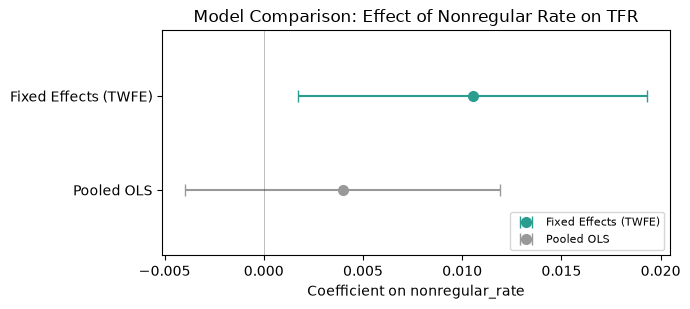

In [34]:
# ── 係数比較プロット（フォレストプロット風）───────────────────────────────────
# 2 モデルの marriage_age 係数と 95% CI を並べる。

# 各モデルの係数・CI を収集
pols_coef_nr = model_pols_nr.params["nonregular_rate"]
pols_ci_nr   = model_pols_nr.conf_int().loc["nonregular_rate"]

fe_coef_nr = model_fe_nr.params["nonregular_rate"]
fe_ci_nr   = model_fe_nr.conf_int().loc["nonregular_rate"]

model_labels = ["Pooled OLS", "Fixed Effects (TWFE)"]
coefs_nr  = [pols_coef_nr, fe_coef_nr]
ci_los_nr = [pols_ci_nr.iloc[0], fe_ci_nr.iloc[0]]
ci_his_nr = [pols_ci_nr.iloc[1], fe_ci_nr.iloc[1]]
colors_dot = ["#999999", "#2A9D8F"]

fig, ax = plt.subplots(figsize=(7, 3.2))
for i, (label, coef, lo, hi, col) in enumerate(
        zip(model_labels, coefs_nr, ci_los_nr, ci_his_nr, colors_dot)):
    ax.errorbar(coef, i,
                xerr=[[coef - lo], [hi - coef]],
                fmt="o", color=col, ecolor=col,
                capsize=4, markersize=7, linewidth=1.5,
                label=label)
    
ax.axvline(0, color="black", linestyle="-", linewidth=0.6, alpha=0.3)
ax.set_yticks(range(len(model_labels)))
ax.set_yticklabels(model_labels)
ax.set_ylim(-0.7, len(model_labels) - 0.3)  # 上下に余白を持たせて中央に寄せる
ax.set_xlabel("Coefficient on nonregular_rate")
ax.set_title("Model Comparison: Effect of Nonregular Rate on TFR")
# 凡例の順序を逆にする
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], fontsize=8, loc="lower right")

plt.tight_layout()
fig.savefig("../images/model_comparison_nr.png", dpi=150, bbox_inches="tight")
plt.show()